# QM9 → Subset and Graph Dataset for GNN / QI-GNN / Quantum GNN

This notebook continues from `QM9_EDA_Preprocessing.ipynb`. It does **not** redo the cleaning or the split. It reuses:

| From the preprocessing notebook | How it is used here |
|---|---|
| `processed/qm9_clean.csv` (130,745 cleaned molecules) | SMILES and `gap_eV` target for each molecule |
| `idx_tr / idx_va / idx_te` in `qm9_gap_eV_processed.npz` | The subset is drawn **inside** these splits, so no molecule changes side |
| `y_tr` (target scaled on the full train set) | Same scaling, so classical and quantum predictions convert back to eV the same way |

This notebook does four things:

1. **Subset**: 10,000 train / 2,000 val / 2,000 test molecules, stratified so the gap distribution and the share of rare fluorine molecules stay the same as in the full data.
2. **Graphs**: each molecule becomes a heavy-atom graph (at most 9 nodes, so at most 9 qubits). Node and edge features follow slide 5 of the proposal.
3. **Two splits** over the same 14,000 molecules: the inherited *random* split and a *scaffold* split (harder, out-of-distribution test).
4. **Save** two versions of the data:
   - a list of PyTorch Geometric `Data` objects for the GNN and QI-GNN,
   - fixed-size padded arrays (9 atoms × features, a 9 × 9 bond-type matrix, and a mask) for the quantum circuit.

## 0. Setup

In [1]:
# Run once if packages are missing
# !pip install torch torch_geometric rdkit pandas numpy matplotlib seaborn scikit-learn

In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch_geometric.data import Data, InMemoryDataset

from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import train_test_split

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
print("torch", torch.__version__)

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.14.1+cu130


### Configuration

In [3]:
PROC_DIR   = "processed"
CLEAN_CSV  = os.path.join(PROC_DIR, "qm9_clean.csv")
PROC_NPZ   = os.path.join(PROC_DIR, "qm9_gap_eV_processed.npz")
OUT_DIR    = os.path.join(PROC_DIR, "graphs")

TARGET     = "gap_eV"
N_TRAIN, N_VAL, N_TEST = 10_000, 2_000, 2_000   # subset sizes
N_GAP_BINS = 10            # strata for the target (deciles of the full train set)
MAX_NODES  = 9             # heavy atoms in QM9 -> qubits in the quantum GNN
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Load the outputs of the preprocessing notebook

`idx_tr / idx_va / idx_te` are row positions in `qm9_clean.csv` (the preprocessing notebook used `idx = np.arange(len(df))` on the same dataframe it saved). The cell below checks this: the scaled `y_tr` in the `.npz`, converted back, must equal `gap_eV` at those rows.

In [4]:
df = pd.read_csv(CLEAN_CSV)
proc = np.load(PROC_NPZ, allow_pickle=True)
idx_full = {"train": proc["idx_tr"], "val": proc["idx_va"], "test": proc["idx_te"]}

# Target scaling used in preprocessing: StandardScaler fit on the full train split (no log1p for gap_eV)
Y_MEAN = float(df[TARGET].values[idx_full["train"]].mean())
Y_STD  = float(df[TARGET].values[idx_full["train"]].std())     # population std, same as StandardScaler

# Alignment check: rows and scaling both match the saved arrays
for name, key in [("train", "y_tr"), ("val", "y_va"), ("test", "y_te")]:
    recon = proc[key] * Y_STD + Y_MEAN
    err = np.abs(recon - df[TARGET].values[idx_full[name]]).max()
    print(f"{name:5s}: {len(idx_full[name]):6,} rows | max |reconstructed - gap_eV| = {err:.2e} eV")
    assert err < 1e-6, "Indices or scaling do not match the preprocessing notebook"

print(f"\nTarget scaling (from full train): mean = {Y_MEAN:.4f} eV, std = {Y_STD:.4f} eV")
df[["mol_id", "can_smiles", TARGET, "n_heavy", "n_F"]].head()

train: 104,595 rows | max |reconstructed - gap_eV| = 1.78e-15 eV
val  : 13,075 rows | max |reconstructed - gap_eV| = 1.78e-15 eV
test : 13,075 rows | max |reconstructed - gap_eV| = 1.78e-15 eV

Target scaling (from full train): mean = 6.8583 eV, std = 1.2837 eV


,mol_id,can_smiles,gap_eV,n_heavy,n_F
0,gdb_1,C,13.736308,1.0,0.0
1,gdb_2,N,9.249150,1.0,0.0
2,gdb_3,O,9.836916,1.0,0.0
3,gdb_4,C#C,9.118535,2.0,0.0
4,gdb_5,C#N,10.329442,2.0,0.0


## 2. Select the subset

A quantum circuit has to be simulated once per molecule per training step, so the full 104k-molecule train set is too slow. We take a smaller subset **inside each existing split**:

- **Strata** = gap decile × contains-fluorine. The gap deciles keep the target distribution. Fluorine is in only 1.45% of molecules, so stratifying on it makes sure the test set still has F molecules for the per-element error analysis.
- The decile edges come from the full **train** set only.
- Because the subset is drawn inside the inherited split, the subset test molecules are a subset of the full test set. Classical models trained on all 104k molecules can therefore be scored on the same 2,000 test molecules.

In [5]:
gap_edges = np.quantile(df[TARGET].values[idx_full["train"]], np.linspace(0, 1, N_GAP_BINS + 1))[1:-1]
df["gap_bin"] = np.digitize(df[TARGET].values, gap_edges)
df["has_F"]   = (df["n_F"] > 0).astype(int)
df["stratum"] = df["gap_bin"] * 2 + df["has_F"]

def stratified_pick(rows, n, seed):
    picked, _ = train_test_split(rows, train_size=n, stratify=df.loc[rows, "stratum"].values,
                                 random_state=seed)
    return np.sort(picked)

sizes = {"train": N_TRAIN, "val": N_VAL, "test": N_TEST}
sub_rows = {s: stratified_pick(idx_full[s], sizes[s], RANDOM_STATE) for s in sizes}

# No molecule may appear in two splits
assert not (set(sub_rows["train"]) & set(sub_rows["val"]) or set(sub_rows["train"]) & set(sub_rows["test"])
            or set(sub_rows["val"]) & set(sub_rows["test"]))
for s in sizes:
    print(f"{s:5s}: {len(sub_rows[s]):,} molecules")

train: 10,000 molecules
val  : 2,000 molecules
test : 2,000 molecules


### 2.1 Does the subset look like the full data?

In [6]:
def describe(rows):
    d = df.loc[rows]
    return pd.Series({
        "n": len(d),
        "gap mean (eV)": d[TARGET].mean(), "gap std (eV)": d[TARGET].std(),
        "gap min": d[TARGET].min(), "gap max": d[TARGET].max(),
        "% with F": 100 * (d["n_F"] > 0).mean(), "% with N": 100 * (d["n_N"] > 0).mean(),
        "% with O": 100 * (d["n_O"] > 0).mean(),
        "% 9 heavy atoms": 100 * (d["n_heavy"] == 9).mean(),
        "% aromatic ring": 100 * (d["n_arom_rings"] > 0).mean(),
    })

comparison = pd.DataFrame({
    "full train": describe(idx_full["train"]), "subset train": describe(sub_rows["train"]),
    "full test":  describe(idx_full["test"]),  "subset val":   describe(sub_rows["val"]),
    "subset test": describe(sub_rows["test"]),
})
comparison.round(3)

,full train,subset train,full test,subset val,subset test
n,104595.000,10000.000,13075.000,2000.000,2000.000
gap mean (eV),6.858,6.861,6.863,6.865,6.858
gap std (eV),1.284,1.285,1.279,1.282,1.274
gap min,0.669,1.633,2.234,2.887,3.385
gap max,13.067,12.044,16.928,9.948,10.177
% with F,1.471,1.460,1.293,1.450,1.350
% with N,61.049,60.850,61.071,60.000,61.500
% with O,85.144,85.290,85.048,85.550,85.050
% 9 heavy atoms,83.369,83.310,83.151,83.600,84.150
% aromatic ring,16.905,16.540,16.275,17.800,16.550


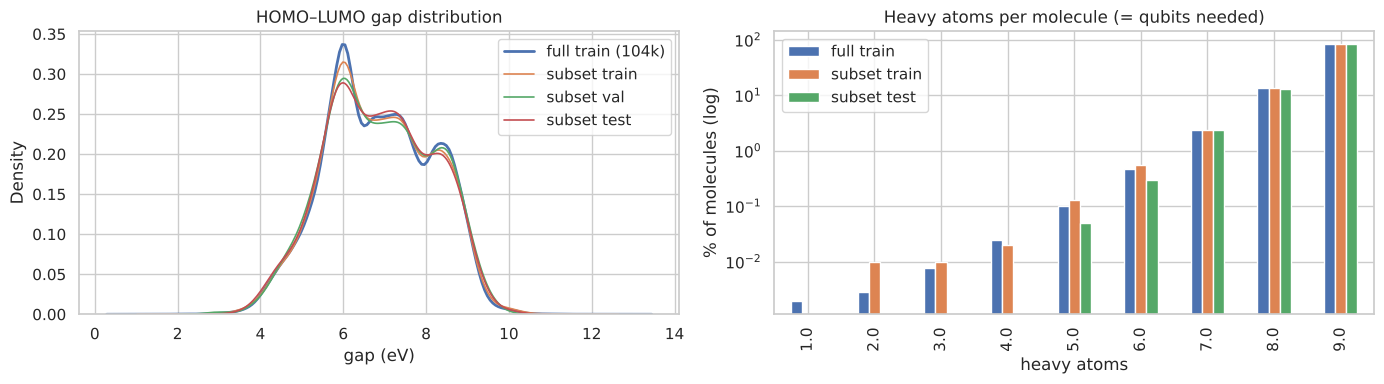

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(df.loc[idx_full["train"], TARGET], ax=axes[0], label="full train (104k)", lw=2)
for s in sizes:
    sns.kdeplot(df.loc[sub_rows[s], TARGET], ax=axes[0], label=f"subset {s}", lw=1.2)
axes[0].set_title("HOMO–LUMO gap distribution"); axes[0].set_xlabel("gap (eV)"); axes[0].legend()

hv = pd.DataFrame({
    "full train": df.loc[idx_full["train"], "n_heavy"].value_counts(normalize=True),
    "subset train": df.loc[sub_rows["train"], "n_heavy"].value_counts(normalize=True),
    "subset test": df.loc[sub_rows["test"], "n_heavy"].value_counts(normalize=True),
}).sort_index() * 100
hv.plot.bar(ax=axes[1], logy=True)
axes[1].set_title("Heavy atoms per molecule (= qubits needed)"); axes[1].set_ylabel("% of molecules (log)")
axes[1].set_xlabel("heavy atoms")
plt.tight_layout(); plt.show()

## 3. Build the molecular graphs

**Heavy-atom graph:** nodes are C, N, O and F atoms. Hydrogens are not nodes; the number of attached H is a node feature instead. This keeps every molecule at **≤ 9 nodes**, which is what lets one qubit stand for one atom in the quantum GNN. All three models use the same node and edge features (slide 5).

| Node feature (23 values) | Encoding |
|---|---|
| Element | one-hot C, N, O, F |
| Heavy-atom degree | one-hot 0–4 |
| Number of attached H | one-hot 0–4 |
| Hybridisation | one-hot sp, sp², sp³, other |
| Aromatic, in ring | 0 / 1 each |
| Formal charge | one-hot −1, 0, +1 (QM9 has some zwitterions such as `[NH3+]` / `[O-]`) |

| Edge feature (6 values) | Encoding |
|---|---|
| Bond type | one-hot single, double, triple, aromatic |
| Conjugated, in ring | 0 / 1 each |

Edges are stored in **both directions**, as message passing expects. 3D coordinates for the QI-GNN are added in a later notebook (they come from the PyG QM9 set, not this CSV).

In [8]:
ELEMENTS   = ["C", "N", "O", "F"]
DEGREES    = [0, 1, 2, 3, 4]
NUM_HS     = [0, 1, 2, 3, 4]
HYBRIDS    = [Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3]
CHARGES    = [-1, 0, 1]
BOND_TYPES = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE, Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]

NODE_FEATURES = ([f"elem_{e}" for e in ELEMENTS] + [f"deg_{d}" for d in DEGREES] + [f"numH_{h}" for h in NUM_HS]
                 + ["hyb_sp", "hyb_sp2", "hyb_sp3", "hyb_other"] + ["aromatic", "in_ring"]
                 + [f"charge_{c:+d}" for c in CHARGES])
EDGE_FEATURES = ["bond_single", "bond_double", "bond_triple", "bond_aromatic", "conjugated", "in_ring"]

def one_hot(value, choices, allow_other=False):
    v = [float(value == c) for c in choices]
    if allow_other:
        v.append(float(value not in choices))
    elif sum(v) == 0:
        raise ValueError(f"Unexpected value {value!r}; expected one of {choices}")
    return v

def atom_features(a):
    return (one_hot(a.GetSymbol(), ELEMENTS) + one_hot(a.GetDegree(), DEGREES)
            + one_hot(a.GetTotalNumHs(), NUM_HS) + one_hot(a.GetHybridization(), HYBRIDS, allow_other=True)
            + [float(a.GetIsAromatic()), float(a.IsInRing())] + one_hot(a.GetFormalCharge(), CHARGES))

def bond_features(b):
    return one_hot(b.GetBondType(), BOND_TYPES) + [float(b.GetIsConjugated()), float(b.IsInRing())]

assert len(NODE_FEATURES) == 23 and len(EDGE_FEATURES) == 6

In [9]:
def mol_to_graph(smiles):
    # Heavy-atom graph for one SMILES: x [n, 23], edge_index [2, 2m], edge_attr [2m, 6], bond-type matrix [n, n]
    mol = Chem.MolFromSmiles(smiles)          # RDKit removes explicit H by default
    n = mol.GetNumAtoms()
    x = np.array([atom_features(a) for a in mol.GetAtoms()], dtype=np.float32)

    src, dst, eattr = [], [], []
    bond_mat = np.zeros((n, n), dtype=np.int8)   # 0 = no bond, 1..4 = single/double/triple/aromatic
    for b in mol.GetBonds():
        i, j, f = b.GetBeginAtomIdx(), b.GetEndAtomIdx(), bond_features(b)
        src += [i, j]; dst += [j, i]; eattr += [f, f]
        bond_mat[i, j] = bond_mat[j, i] = BOND_TYPES.index(b.GetBondType()) + 1
    edge_index = np.array([src, dst], dtype=np.int64).reshape(2, -1)
    edge_attr  = np.array(eattr, dtype=np.float32).reshape(-1, len(EDGE_FEATURES))
    return x, edge_index, edge_attr, bond_mat

# Try it on one molecule
ex = df.loc[sub_rows["train"][0]]
x, ei, ea, bm = mol_to_graph(ex["can_smiles"])
print(ex["mol_id"], ex["can_smiles"], f"| gap = {ex[TARGET]:.3f} eV")
print("nodes:", x.shape[0], "| directed edges:", ei.shape[1])
print(pd.DataFrame(x, columns=NODE_FEATURES).loc[:, lambda t: t.sum() > 0].astype(int))
print("bond-type matrix:\n", bm)

gdb_7 CC | gap = 12.044 eV
nodes: 2 | directed edges: 2
   elem_C  deg_1  numH_3  hyb_sp3  charge_+0
0       1      1       1        1          1
1       1      1       1        1          1
bond-type matrix:
 [[0 1]
 [1 0]]


### 3.1 Scaffold split over the same 14,000 molecules

Molecules that share a Bemis–Murcko scaffold go to the same split, so the test set contains ring systems the model has not seen. This is the same rule as the `SPLIT = "scaffold"` option in the preprocessing notebook: the largest scaffold groups fill train first, then val, then test. Here the split is applied to the 14,000 subset molecules, using the same 10k / 2k / 2k sizes. Acyclic molecules all share the empty scaffold and form one large group, which goes to train.

In [10]:
order_rows = np.concatenate([sub_rows["train"], sub_rows["val"], sub_rows["test"]])
sub = df.loc[order_rows].reset_index().rename(columns={"index": "row"})   # `row` = position in qm9_clean.csv
sub["split_random"] = ["train"] * N_TRAIN + ["val"] * N_VAL + ["test"] * N_TEST

sub["scaffold"] = [MurckoScaffold.MurckoScaffoldSmiles(smiles=s) for s in sub["can_smiles"]]
groups = sorted(sub.groupby("scaffold").indices.values(), key=len, reverse=True)
scaf_split = np.empty(len(sub), dtype=object)
n_tr = n_va = 0
for g in groups:
    if n_tr + len(g) <= N_TRAIN:
        scaf_split[g] = "train"; n_tr += len(g)
    elif n_va + len(g) <= N_VAL:
        scaf_split[g] = "val"; n_va += len(g)
    else:
        scaf_split[g] = "test"
sub["split_scaffold"] = scaf_split

print("Unique scaffolds in subset:", sub["scaffold"].nunique())
print(sub["split_scaffold"].value_counts().reindex(["train", "val", "test"]))
tr_scaf = set(sub.loc[sub.split_scaffold == "train", "scaffold"])
te_scaf = set(sub.loc[sub.split_scaffold == "test", "scaffold"])
print("Scaffolds shared by scaffold-train and scaffold-test:", len(tr_scaf & te_scaf))
print("\nGap (eV) by scaffold split:")
print(sub.groupby("split_scaffold")[TARGET].agg(["mean", "std"]).round(3))

Unique scaffolds in subset: 3389
split_scaffold
train    10000
val       2000
test      2000
Name: count, dtype: int64
Scaffolds shared by scaffold-train and scaffold-test: 0

Gap (eV) by scaffold split:
                 mean    std
split_scaffold              
test            6.747  1.380
train           6.913  1.261
val             6.712  1.270


### 3.2 Featurise all subset molecules

In [11]:
graphs, X_pad, B_pad, M_pad = [], [], [], []
n_feat = len(NODE_FEATURES)

for k, r in enumerate(sub.itertuples(index=False)):
    x, ei, ea, bm = mol_to_graph(r.can_smiles)
    n = x.shape[0]
    assert n <= MAX_NODES and n == r.n_heavy, f"{r.mol_id}: {n} nodes"
    y_scaled = (getattr(r, TARGET) - Y_MEAN) / Y_STD

    graphs.append(Data(
        x=torch.from_numpy(x), edge_index=torch.from_numpy(ei), edge_attr=torch.from_numpy(ea),
        y=torch.tensor([[y_scaled]], dtype=torch.float32),            # scaled target (train on this)
        y_eV=torch.tensor([[getattr(r, TARGET)]], dtype=torch.float32),  # original units (report MAE on this)
        row=torch.tensor([r.row]), sub_idx=torch.tensor([k]),
        smiles=r.can_smiles, mol_id=r.mol_id,
    ))

    # Fixed-size copy for the quantum circuit: pad to 9 atoms
    xp = np.zeros((MAX_NODES, n_feat), dtype=np.float32); xp[:n] = x
    bp = np.zeros((MAX_NODES, MAX_NODES), dtype=np.int8); bp[:n, :n] = bm
    mp = np.zeros(MAX_NODES, dtype=bool); mp[:n] = True
    X_pad.append(xp); B_pad.append(bp); M_pad.append(mp)

X_pad, B_pad, M_pad = np.stack(X_pad), np.stack(B_pad), np.stack(M_pad)
print(f"{len(graphs):,} graphs | padded arrays: X {X_pad.shape}, bonds {B_pad.shape}, mask {M_pad.shape}")
graphs[0]

14,000 graphs | padded arrays: X (14000, 9, 23), bonds (14000, 9, 9), mask (14000, 9)


Data(x=[2, 23], edge_index=[2, 2], edge_attr=[2, 6], y=[1, 1], y_eV=[1, 1], row=[1], sub_idx=[1], smiles='CC', mol_id='gdb_7')

### 3.3 Sanity checks on the graphs

In [12]:
n_nodes = np.array([g.num_nodes for g in graphs])
n_edges = np.array([g.edge_index.shape[1] // 2 for g in graphs])

checks = {
    "max nodes (must be <= 9)": n_nodes.max(),
    "graphs with a single atom (no edges)": int((n_nodes == 1).sum()),
    "every node has exactly one element": bool((X_pad[M_pad][:, :4].sum(1) == 1).all()),
    "padding rows are all zero": bool((X_pad[~M_pad] == 0).all()),
    "bond matrices symmetric": bool((B_pad == B_pad.transpose(0, 2, 1)).all()),
    "no bonds touching padding": bool((B_pad[~M_pad] == 0).all()),
    "edge count matches bond matrix": bool(((B_pad > 0).sum((1, 2)) // 2 == n_edges).all()),
    "isolated atoms in multi-atom molecules": int(sum(
        (np.bincount(g.edge_index[0].numpy(), minlength=g.num_nodes) == 0).sum()
        for g in graphs if g.num_nodes > 1)),
}
for k, v in checks.items():
    print(f"{k:45s} {v}")

print(f"\nNodes per graph: mean {n_nodes.mean():.2f} | bonds per graph: mean {n_edges.mean():.2f}")

max nodes (must be <= 9)                      9
graphs with a single atom (no edges)          0
every node has exactly one element            True
padding rows are all zero                     True
bond matrices symmetric                       True
no bonds touching padding                     True
edge count matches bond matrix                True
isolated atoms in multi-atom molecules        0

Nodes per graph: mean 8.80 | bonds per graph: mean 9.42


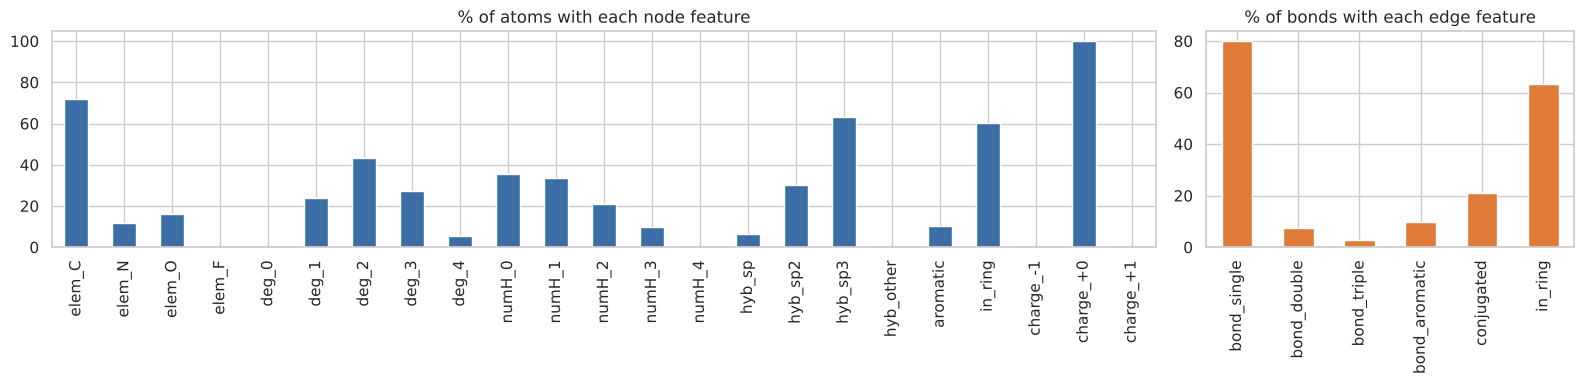

Node features never on in the subset: ['deg_0', 'numH_4', 'hyb_other']


In [13]:
# How often each node / edge feature is "on" — columns that are never on carry no information
node_freq = pd.Series(X_pad[M_pad].mean(0) * 100, index=NODE_FEATURES).round(2)
edge_freq = pd.Series(torch.cat([g.edge_attr for g in graphs]).mean(0).numpy() * 100, index=EDGE_FEATURES).round(2)

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1]})
node_freq.plot.bar(ax=axes[0], color="#3b6ea5"); axes[0].set_title("% of atoms with each node feature")
edge_freq.plot.bar(ax=axes[1], color="#e07b39"); axes[1].set_title("% of bonds with each edge feature")
plt.tight_layout(); plt.show()
print("Node features never on in the subset:", list(node_freq[node_freq == 0].index))

## 4. Save

| File | Contents | Used by |
|---|---|---|
| `graphs/qm9_gap_subset_graphs.pt` | the 14,000 PyG graphs, collated (InMemoryDataset format), + both splits + metadata | GNN, QI-GNN |
| `graphs/qm9_gap_subset_qgnn.npz` | `X` [14000, 9, 23], `bonds` [14000, 9, 9] (0 = none, 1–4 = bond type), `mask` [14000, 9], `y`, `y_eV`, split positions | Quantum GNN |
| `graphs/qm9_gap_subset_index.csv` | one row per molecule: row in `qm9_clean.csv`, `mol_id`, SMILES, scaffold, both split labels | Joining results back to molecules |
| `graphs/qm9_gap_subset_meta.json` | feature names, target scaling, sizes, seed | Reproducibility |

Split positions are indices into the 14,000-molecule list (0 … 13,999), the same for the `.pt` and `.npz` files.

In [14]:
splits = {
    name: {s: np.where(sub[col].values == s)[0] for s in ["train", "val", "test"]}
    for name, col in [("random", "split_random"), ("scaffold", "split_scaffold")]
}
meta = {
    "source_notebook": "QM9_EDA_Preprocessing.ipynb", "target": TARGET,
    "y_mean_eV": Y_MEAN, "y_std_eV": Y_STD,
    "note": "y = (gap_eV - y_mean_eV) / y_std_eV, scaler fit on the FULL train split (104,595 molecules)",
    "sizes": sizes, "random_state": RANDOM_STATE, "max_nodes": MAX_NODES,
    "node_features": NODE_FEATURES, "edge_features": EDGE_FEATURES,
    "bond_codes": {"0": "none", "1": "single", "2": "double", "3": "triple", "4": "aromatic"},
    "stratified_on": f"{N_GAP_BINS} gap bins (full-train quantiles) x contains-F",
}

# Collate the 14,000 graphs into one big graph + slice table (much smaller on disk than a list)
data_all, slices_all = InMemoryDataset.collate(graphs)
torch.save({"data": data_all, "slices": slices_all,
            "splits": {k: {s: torch.from_numpy(v) for s, v in d.items()} for k, d in splits.items()},
            "meta": meta},
           os.path.join(OUT_DIR, "qm9_gap_subset_graphs.pt"))

np.savez_compressed(
    os.path.join(OUT_DIR, "qm9_gap_subset_qgnn.npz"),
    X=X_pad, bonds=B_pad, mask=M_pad, n_nodes=n_nodes,
    y=((sub[TARGET].values - Y_MEAN) / Y_STD).astype(np.float32), y_eV=sub[TARGET].values.astype(np.float32),
    row=sub["row"].values, node_features=np.array(NODE_FEATURES),
    **{f"{k}_{s}": v for k, d in splits.items() for s, v in d.items()},
)

sub[["row", "mol_id", "can_smiles", TARGET, "n_heavy", "n_F", "scaffold", "split_random", "split_scaffold"]] \
    .rename_axis("sub_idx").to_csv(os.path.join(OUT_DIR, "qm9_gap_subset_index.csv"))
with open(os.path.join(OUT_DIR, "qm9_gap_subset_meta.json"), "w") as f:
    json.dump(meta, f, indent=2)

for fn in sorted(os.listdir(OUT_DIR)):
    print(f"{fn:35s} {os.path.getsize(os.path.join(OUT_DIR, fn)) / 1e6:6.2f} MB")

qm9_gap_subset_graphs.pt             24.08 MB
qm9_gap_subset_index.csv              1.14 MB
qm9_gap_subset_meta.json              0.00 MB
qm9_gap_subset_qgnn.npz               0.48 MB


## 5. How to load the data in the next notebooks

The cell below reloads both files, as the model notebooks will. `weights_only=False` is needed because the file holds PyG objects, not only tensors (only load files you created yourself this way). Copy the `QM9Subset` class into each model notebook.

In [15]:
from torch_geometric.loader import DataLoader

# --- Classical GNN / QI-GNN ---
class QM9Subset(InMemoryDataset):
    # Reads the collated file saved above; dataset[i] gives one Data object
    def __init__(self, path):
        super().__init__(root=None)
        blob = torch.load(path, weights_only=False)
        self.data, self.slices = blob["data"], blob["slices"]
        self.splits, self.meta = blob["splits"], blob["meta"]

ds = QM9Subset(os.path.join(OUT_DIR, "qm9_gap_subset_graphs.pt"))
SPLIT = "random"                                   # or "scaffold"
train_set = ds[ds.splits[SPLIT]["train"]]
val_set   = ds[ds.splits[SPLIT]["val"]]
test_set  = ds[ds.splits[SPLIT]["test"]]
print(len(ds), "graphs | train/val/test:", len(train_set), len(val_set), len(test_set))
assert torch.equal(ds[5].x, graphs[5].x) and ds[5].smiles == graphs[5].smiles   # round-trip check
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
batch = next(iter(train_loader))
print(batch)

# --- Quantum GNN: fixed 9-qubit arrays ---
q = np.load(os.path.join(OUT_DIR, "qm9_gap_subset_qgnn.npz"))
tr = q[f"{SPLIT}_train"]
print("X", q["X"][tr].shape, "| bonds", q["bonds"][tr].shape, "| mask", q["mask"][tr].shape, "| y", q["y"][tr].shape)

# Predictions come back to eV with: pred_eV = pred_scaled * y_std_eV + y_mean_eV
m = ds.meta
print(f"Scaled-target std is {m['y_std_eV']:.3f} eV, so an MAE of 0.1 in scaled units = {0.1 * m['y_std_eV']:.3f} eV")

14000 graphs | train/val/test: 10000 2000 2000
DataBatch(x=[567, 23], edge_index=[2, 1212], edge_attr=[1212, 6], y=[64, 1], y_eV=[64, 1], row=[64], sub_idx=[64], smiles=[64], mol_id=[64], batch=[567], ptr=[65])
X (10000, 9, 23) | bonds (10000, 9, 9) | mask (10000, 9) | y (10000,)
Scaled-target std is 1.284 eV, so an MAE of 0.1 in scaled units = 0.128 eV


### Summary

- The **subset** has 10k / 2k / 2k molecules drawn from inside the original split, stratified on gap decile × fluorine. Section 2.1 checks that it matches the full data.
- Every molecule is a **heavy-atom graph with at most 9 nodes**: 23 node features and 6 edge features, shared by all three models.
- The same 14,000 molecules have two splits: **random** (inherited) and **scaffold** (out-of-distribution).
- The **quantum-ready arrays** pad every molecule to 9 atoms. The bond-type matrix sets which qubit pairs get an entangling gate. Code 0 means no bond, so that gate is the identity.

**Next:** train the classical GNN (GIN) on this subset and on the full data. That gives the baseline before the quantum circuit is written.